1. Загрузить изображение


In [2]:
import cv2
import matplotlib.pyplot as plt
from google.colab import files

In [3]:
image = cv2.imread("heroImage.jpg")

Изображение успешно загружено
Размер: (2280, 3420, 3)


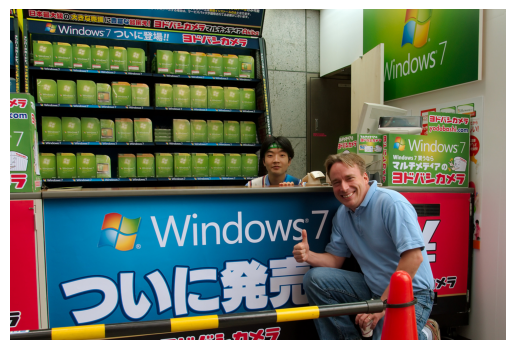

In [11]:
image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

plt.imshow(image_rgb)
plt.axis("off")
plt.show()

2. Построить гистограмму по каждому из каналов (RGB) (не разрешается пользоваться готовыми реализациями)


In [6]:
blue_histogram = [0] * 256
green_histogram = [0] * 256
red_histogram = [0] * 256

height, width, channels = image.shape

for y in range(height):
    for x in range(width):
        b, g, r = image[y, x]

        blue_histogram[b] += 1
        green_histogram[g] += 1
        red_histogram[r] += 1

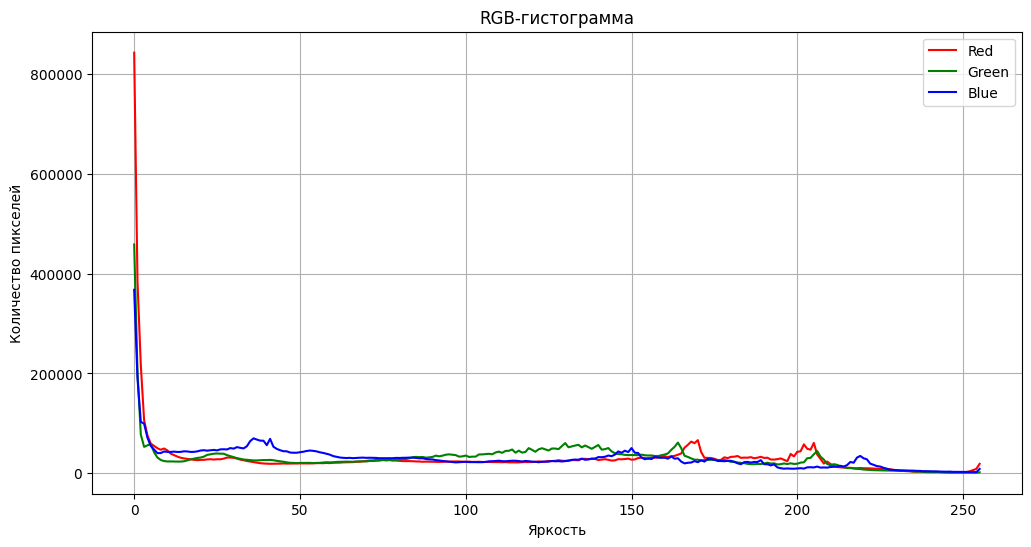

In [10]:
values = range(256)

plt.figure(figsize=(12, 6))

plt.plot(values, red_histogram, label="Red", color="red")
plt.plot(values, green_histogram, label="Green", color="green")
plt.plot(values, blue_histogram, label="Blue", color="blue")

plt.xlabel("Яркость")
plt.ylabel("Количество пикселей")
plt.title("RGB-гистограмма")

plt.legend()
plt.grid()

plt.show()


Дополнительно:
Построить метрики для оценки экспозиции кадра.
1. Доля пикселей, яркость всех каналов которых равна 255 (для 8-битных изображений).
2. Доля пикселей, яркость всех каналов которых равна 0.
3. Доля пикселей, яркость всех каналов которых находится в диапазоне 5-95% от максимальной яркости пикселя.

In [9]:
white_pixels = 0
black_pixels = 0
normal_pixels = 0

total_pixels = width * height

min_brightness = 255 * 0.05
max_brightness = 255 * 0.95

for y in range(height):
    for x in range(width):
        b, g, r = image[y, x]

        if r == 255 and g == 255 and b == 255:
            white_pixels += 1

        if r == 0 and g == 0 and b == 0:
            black_pixels += 1

        if min_brightness <= r <= max_brightness \
           and min_brightness <= g <= max_brightness \
           and min_brightness <= b <= max_brightness:
           normal_pixels += 1

white_ratio = white_pixels / total_pixels
black_ratio = black_pixels / total_pixels
normal_ratio = normal_pixels / total_pixels

In [12]:
print("Всего пикселей:", total_pixels)

print(
    f"Доля белых пикселей: "
    f"{white_ratio:.4f} = {white_ratio * 100:.2f}%"
)

print(
    f"Доля чёрных пикселей: "
    f"{black_ratio:.4f} = {black_ratio * 100:.2f}%"
)

print(
    f"Доля пикселей в диапазоне 5-95%: "
    f"{normal_ratio:.4f} = {normal_ratio * 100:.2f}%"
)

Всего пикселей: 7797600
Доля белых пикселей: 0.0000 = 0.00%
Доля чёрных пикселей: 0.0082 = 0.82%
Доля пикселей в диапазоне 5-95%: 0.6159 = 61.59%
